# 02 Raster processing: population-weighted PM2.5 by division, district and upazila

Turns the raw grids from notebook 01 into the tables every later step uses: how much PM2.5 the average person breathes in each area, each year and each month, and how many people live in each WHO exposure band.

**What this notebook does**
1. Cleans the boundaries: one copy of each level, codes as keys, current official spellings
2. Places every populated 100 m WorldPop cell in its upazila and on the PM2.5 grids
3. Computes population-weighted and simple area means for every upazila, district, division and the whole country, for 1998 to 2024
4. Counts people in each WHO band (guideline and the four interim targets)
5. Does the same for every month at 0.1°
6. Checks the data: population kept, real gaps inside the border, and the 2018 jump

**Why population-weighted:** a simple average of the grid treats empty char land, rivers and forest the same as Dhaka city. Weighting each cell by the people living in it gives the exposure of the average resident, which is the measure WHO and the Global Burden of Disease use.

**Why work at 100 m:** every populated 100 m WorldPop cell is assigned to its upazila and to the PM2.5 cell it falls in. That way the boundaries are followed closely, and no population is lost or double-counted where an upazila edge cuts through a 1 km PM2.5 cell.

**Fixes carried over from the notebook 01 first look**
- **Missing data measure:** notebook 01 reported 53.5% missing, but that counted the empty corners of the crop box outside the border. Here, missing data is counted only for cells inside Bangladesh and for people, so 0% really means no gaps.
- **The 2018 jump:** 2018 was about 77 µg/m³ against 55 to 64 in nearby years. Section 6 checks it three ways before it is trusted: annual vs monthly data, which months drive it, and the previous ACAG release (V6.GL.02.04).
- **Duplicate boundary layers:** the unzipped HDX folder ends in `.shp`, so notebook 01 listed every layer twice. Here only real shapefiles are read, and each level is picked once by its feature count and geometry type.

**Outputs** (all in `data/processed/`)
- `bgd_admin.gpkg`: division, district and upazila layers with codes, harmonised names and area
- `pm25_annual_grid.nc`: the 0.01° PM2.5 cube for 1998 to 2024 plus 2022 population on the same grid, for the per-pixel trend tests in R
- `pm25_unit_year.parquet`: every area and year, with population-weighted mean, area mean and population
- `pm25_unit_month.parquet`: every area and month, population-weighted mean
- `pm25_who_bands.parquet`: people in each WHO band, every area and year
- `qa_checks.csv`: the checks below, saved

In [1]:
%pip install -q rioxarray netCDF4 pyogrio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 45.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 58.6 MB/s eta 0:00:00


In [2]:
import pandas as pd, numpy as np, xarray as xr, geopandas as gpd, rioxarray, pyogrio, rasterio.features, requests, pathlib, shutil, tempfile, os
import matplotlib.pyplot as plt
from rasterio.transform import from_origin
from urllib.parse import quote
from tqdm.auto import tqdm

try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = pathlib.Path("/content/drive/MyDrive/Bangladesh Air Pollution Project")
except ImportError:
    ROOT = pathlib.Path.cwd().parent

RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "outputs" / "figures"
for d in (PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"
TMP = pathlib.Path(tempfile.gettempdir()) / "pm25_tmp"
TMP.mkdir(exist_ok=True)

YEARS = sorted(int(p.stem[-4:]) for p in (RAW / "pm25" / "annual").glob("pm25_annual_*.nc"))
BANDS = ["<=5 guideline", "5-10 IT-4", "10-15 IT-3", "15-25 IT-2", "25-35 IT-1", ">35 above IT-1"]
LIMITS = [5, 10, 15, 25, 35]
qa = []
print(f"{len(YEARS)} annual files, {YEARS[0]} to {YEARS[-1]}")

Mounted at /content/drive
27 annual files, 1998 to 2024


## 1. Boundaries

Only real `.shp` files are read (fix 3), and each level is picked by geometry type and feature count: 8 polygons for divisions, 64 for districts, about 507 for upazilas. The point layer of capitals also has 507 features, which is why the geometry type matters.

**Keys:** the BBS place codes (`pcode`) are used to join levels, not names, because names are spelled in several ways. Each upazila gets its district and division code from its district, so the three levels always nest.

**Spellings:** five districts were renamed in 2018 (Chattogram, Barishal, Cumilla, Jashore, Bogura). Any old spelling left in the files is replaced, and the list of changes is printed.

**Area:** computed in an equal-area projection (EPSG:6933), so km² values are correct everywhere in the country.

In [3]:
shp = pd.DataFrame([{"path": p, **{k: pyogrio.read_info(p)[k] for k in ("features", "geometry_type")}} for p in (RAW / "boundaries").rglob("*.shp") if p.is_file()])
pick = lambda n: gpd.read_file(shp.query("geometry_type.str.contains('Polygon') and features.between(@n[0], @n[1])", engine="python")["path"].iloc[0]).to_crs(4326)
FIX = {r"\bChittagong\b": "Chattogram", r"\bBarisal\b": "Barishal", r"\bComilla\b": "Cumilla", r"\bJessore\b": "Jashore", r"\bBogra\b": "Bogura"}

division = pick((8, 8)).rename(columns={"adm1_pcode": "pcode", "adm1_name": "name"})[["pcode", "name", "geometry"]]
district = pick((64, 64)).rename(columns={"adm2_pcode": "pcode", "adm2_name": "name", "adm1_pcode": "division_pcode"})[["pcode", "name", "division_pcode", "geometry"]]
upazila = (pick((480, 560)).rename(columns={"adm3_pcode": "pcode", "adm3_name": "name", "adm2_pcode": "district_pcode"})[["pcode", "name", "district_pcode", "geometry"]]
           .merge(district[["pcode", "division_pcode"]].rename(columns={"pcode": "district_pcode"}), how="left"))
assert upazila["division_pcode"].notna().all() and district["division_pcode"].isin(division["pcode"]).all(), "Some upazilas or districts do not match a parent code"

changes = []
for g in (division, district, upazila):
    new = g["name"].replace(FIX, regex=True)
    changes += [f"{a} -> {b}" for a, b in zip(g["name"], new) if a != b]
    g["name"] = new
    g["area_km2"] = g.to_crs(6933).area / 1e6
print(f"Divisions {len(division)}, districts {len(district)}, upazilas {len(upazila)}")
print("Spelling changes:", sorted(set(changes)) or "none needed")
for lvl, g in {"division": division, "district": district, "upazila": upazila}.items():
    g.to_file(PROC / "bgd_admin.gpkg", layer=lvl, driver="GPKG")
pd.DataFrame({"level": ["division", "district", "upazila"], "units": [len(division), len(district), len(upazila)], "area_km2": [g["area_km2"].sum().round() for g in (division, district, upazila)]})

Divisions 8, districts 64, upazilas 507
Spelling changes: none needed


,level,units,area_km2
0,division,8,145962.0
1,district,64,145962.0
2,upazila,507,145962.0


The three levels should cover the same total area (about 147,000 km²). Small differences come from coastline detail.

## 2. Population cells

Every 100 m WorldPop cell with people in it becomes one row: its population, the upazila it falls in, and the PM2.5 cell it sits in on the 0.01° (annual) and 0.1° (monthly) grids.

A few populated cells along the coast and rivers fall just outside the upazila polygons, because WorldPop and BBS draw the coastline slightly differently. These are assigned to the nearest upazila rather than dropped, and the number of people moved and the largest distance are printed.

In [4]:
pop = rioxarray.open_rasterio(RAW / "worldpop" / "bgd_pop_2022_CN_100m_R2025A_v1.tif", masked=True).squeeze(drop=True)
P = pop.values
r, c = np.nonzero(np.nan_to_num(P) > 0)
w, lon, lat = P[r, c].astype("float64"), pop.x.values[c], pop.y.values[r]
uid = rasterio.features.rasterize(zip(upazila.geometry, range(len(upazila))), out_shape=P.shape, transform=pop.rio.transform(), fill=-1, dtype="int32")[r, c]
del P

miss = uid < 0
if miss.any():
    pts = gpd.GeoDataFrame(geometry=gpd.points_from_xy(lon[miss], lat[miss]), crs=4326).to_crs(6933)
    near = gpd.sjoin_nearest(pts, upazila[["geometry"]].reset_index(drop=True).to_crs(6933), distance_col="m").groupby(level=0).first()
    uid[miss] = near["index_right"].values
    qa.append({"check": "people snapped to nearest upazila", "value": f"{w[miss].sum():,.0f} ({w[miss].sum() / w.sum():.3%}), max {near['m'].max() / 1000:.1f} km"})
print(f"Populated cells: {len(w):,} | total population {w.sum():,.0f} | outside polygons: {miss.sum():,} cells, {w[miss].sum():,.0f} people")
qa.append({"check": "population total", "value": f"{w.sum():,.0f}"})

Populated cells: 10,340,494 | total population 168,343,283 | outside polygons: 2,647 cells, 21,135 people


In [5]:
def flat_index(da):
    i = np.rint((lat - float(da["lat"][0])) / float(da["lat"][1] - da["lat"][0])).astype(int)
    j = np.rint((lon - float(da["lon"][0])) / float(da["lon"][1] - da["lon"][0])).astype(int)
    assert i.min() >= 0 and i.max() < da.sizes["lat"] and j.min() >= 0 and j.max() < da.sizes["lon"], "Some people fall outside the PM2.5 grid"
    return i * da.sizes["lon"] + j

ann = xr.concat([xr.open_dataarray(RAW / "pm25" / "annual" / f"pm25_annual_{y}.nc").expand_dims(year=[y]) for y in YEARS], "year").load()
mon = xr.concat([xr.open_dataarray(p) for p in sorted((RAW / "pm25" / "monthly").glob("pm25_monthly_*.nc"))], "time").load()
fa, fm = flat_index(ann), flat_index(mon)
pop_grid = xr.DataArray(np.bincount(fa, w, ann.sizes["lat"] * ann.sizes["lon"]).reshape(ann.sizes["lat"], ann.sizes["lon"]), coords={"lat": ann["lat"], "lon": ann["lon"]}, name="pop_2022")
xr.Dataset({"pm25": ann, "pop_2022": pop_grid}).to_netcdf(TMP / "pm25_annual_grid.nc")
shutil.move(TMP / "pm25_annual_grid.nc", PROC / "pm25_annual_grid.nc")
print(f"Annual grid {ann.sizes['lat']} x {ann.sizes['lon']}, monthly grid {mon.sizes['lat']} x {mon.sizes['lon']} x {mon.sizes['time']} months | population on 0.01 deg grid: {float(pop_grid.sum()):,.0f}")

Annual grid 620 x 490, monthly grid 62 x 49 x 324 months | population on 0.01 deg grid: 168,343,283


## 3. Inside-the-border mask and real gaps (fix 1)

Each 0.01° cell whose centre is inside an upazila gets that upazila's number; cells outside Bangladesh get -1. Missing data is then counted two ways, both only inside the border:
- **cells:** share of 0.01° cells inside Bangladesh with no PM2.5 value
- **people:** share of the population living in a cell with no PM2.5 value

The same cell-to-upazila map gives the simple area mean per area, used next to the population-weighted mean to show how much weighting matters. A few very small upazilas (mostly city corporation units) may have no cell centre inside them; they get a population-weighted value but no area mean.

In [6]:
dx, dy = float(ann["lon"][1] - ann["lon"][0]), float(ann["lat"][1] - ann["lat"][0])
zone = np.flipud(rasterio.features.rasterize(zip(upazila.geometry, range(len(upazila))), out_shape=(ann.sizes["lat"], ann.sizes["lon"]), transform=from_origin(float(ann["lon"][0]) - dx / 2, float(ann["lat"][-1]) + dy / 2, dx, dy), fill=-1, dtype="int32")).ravel()
inside = zone >= 0
gaps = pd.DataFrame({
    "year": YEARS,
    "missing_cells_inside_%": [np.isnan(ann.values[k].ravel()[inside]).mean() * 100 for k in range(len(YEARS))],
    "missing_people_%": [w[np.isnan(ann.values[k].ravel()[fa])].sum() / w.sum() * 100 for k in range(len(YEARS))],
}).round(3)
qa += [{"check": "cells inside Bangladesh (0.01 deg)", "value": f"{inside.sum():,}"},
       {"check": "max missing cells inside border, any year", "value": f"{gaps['missing_cells_inside_%'].max()}%"},
       {"check": "max missing people, any year", "value": f"{gaps['missing_people_%'].max()}%"},
       {"check": "upazilas with no 0.01 deg cell centre", "value": int((np.bincount(zone[inside], minlength=len(upazila)) == 0).sum())}]
gaps.set_index("year").T

year,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
missing_cells_inside_%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
missing_people_%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Annual means and WHO bands

For each year, two sums are kept per upazila: population x PM2.5 and population. Districts, divisions and the country are built by adding up their upazilas' sums and dividing at the end, so every level uses exactly the same people and the national figure is not an average of averages.

**WHO 2021 bands** (annual mean, µg/m³): the guideline is 5, with interim targets IT-4 at 10, IT-3 at 15, IT-2 at 25 and IT-1 at 35. Each person is counted in the band of the cell they live in.

In [7]:
def sums(v, idx):
    ok = ~np.isnan(v[idx])
    return np.bincount(uid[ok], w[ok] * v[idx][ok], len(upazila)), np.bincount(uid[ok], w[ok], len(upazila))

rows, band_rows = [], []
for k, y in enumerate(tqdm(YEARS, desc="Years")):
    v = ann.values[k].ravel()
    pxp, p = sums(v, fa)
    a_sum, a_n = np.bincount(zone[inside], np.nan_to_num(v[inside]), len(upazila)), np.bincount(zone[inside], ~np.isnan(v[inside]), len(upazila))
    rows.append(pd.DataFrame({"upazila_pcode": upazila["pcode"], "year": y, "pm_x_pop": pxp, "pop": p, "pm_x_cell": a_sum, "cells": a_n}))
    vv = v[fa]
    b = np.searchsorted(LIMITS, vv, side="left")
    ok = ~np.isnan(vv)
    band_rows.append(pd.DataFrame({"upazila_pcode": np.repeat(upazila["pcode"].values, len(BANDS)), "year": y, "band": np.tile(BANDS, len(upazila)),
                                   "people": np.bincount(uid[ok] * len(BANDS) + b[ok], w[ok], len(upazila) * len(BANDS))}))
base = pd.concat(rows, ignore_index=True)
bands = pd.concat(band_rows, ignore_index=True)

lookup = upazila[["pcode", "district_pcode", "division_pcode"]].rename(columns={"pcode": "upazila_pcode"}).assign(national="BD")
names = pd.concat([g[["pcode", "name"]] for g in (upazila, district, division)] + [pd.DataFrame({"pcode": ["BD"], "name": ["Bangladesh"]})])

def roll(df, value_cols):
    return pd.concat([df.merge(lookup).groupby([key, *[c for c in df.columns if c in ("year", "date", "band")]], as_index=False)[value_cols].sum().rename(columns={key: "pcode"}).assign(level=lvl)
                      for lvl, key in {"upazila": "upazila_pcode", "district": "district_pcode", "division": "division_pcode", "national": "national"}.items()], ignore_index=True).merge(names, how="left")

unit_year = roll(base, ["pm_x_pop", "pop", "pm_x_cell", "cells"]).assign(pm25_popw=lambda d: d["pm_x_pop"] / d["pop"], pm25_area=lambda d: d["pm_x_cell"] / d["cells"].where(d["cells"] > 0))
unit_year = unit_year[["level", "pcode", "name", "year", "pop", "pm25_popw", "pm25_area"]].sort_values(["level", "pcode", "year"])
who = roll(bands, ["people"]).assign(share=lambda d: d["people"] / d.groupby(["level", "pcode", "year"])["people"].transform("sum"))[["level", "pcode", "name", "year", "band", "people", "share"]]
unit_year.to_parquet(PROC / "pm25_unit_year.parquet", index=False)
who.to_parquet(PROC / "pm25_who_bands.parquet", index=False)
nat = unit_year.query("level == 'national'").set_index("year")
qa.append({"check": "population in weighted means (national, any year)", "value": f"{nat['pop'].min():,.0f} to {nat['pop'].max():,.0f}"})
unit_year.groupby("level").agg(units=("pcode", "nunique"), rows=("pcode", "size"), min_pm25=("pm25_popw", "min"), max_pm25=("pm25_popw", "max"), missing_area_mean=("pm25_area", lambda s: s.isna().sum())).round(1)

Years:   0%|          | 0/27 [00:00<?, ?it/s]

,units,rows,min_pm25,max_pm25,missing_area_mean
level,,,,,
district,64,1728,16.2,104.7,0
division,8,216,20.2,96.8,0
national,1,27,39.2,83.3,0
upazila,507,13689,13.7,108.7,0


year,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
pm25_popw,39.2,41.9,51.9,47.6,49.8,54.6,52.3,52.9,60.9,56.3,...,64.9,65.2,60.5,83.3,69.5,70.3,76.1,59.8,67.2,64.9
pm25_area,36.2,38.4,47.3,43.9,45.6,50.2,48.5,48.1,55.7,52.4,...,60.6,61.0,55.9,77.0,64.2,64.9,69.6,55.0,61.3,59.6


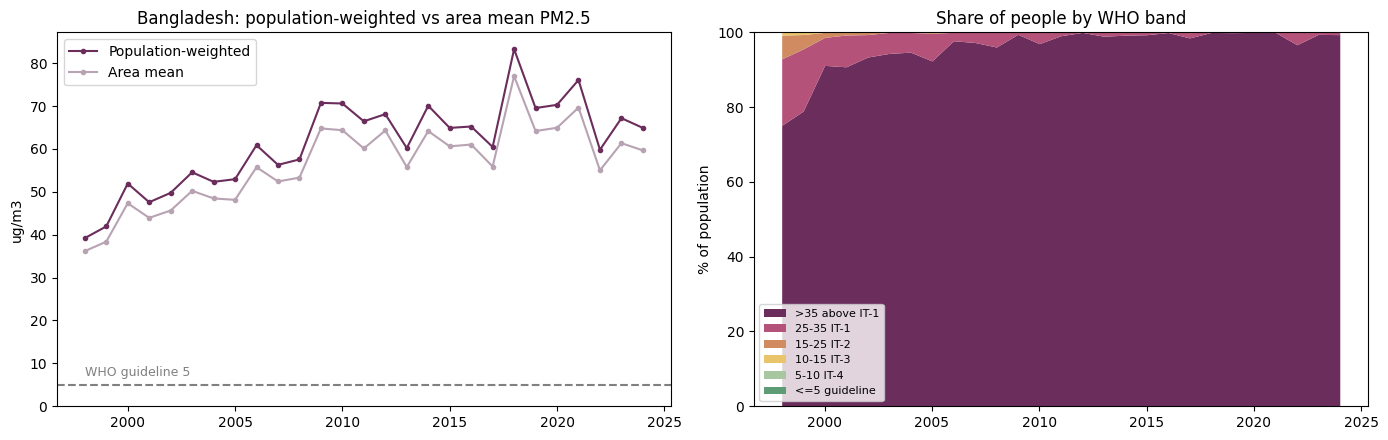

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
nat[["pm25_popw", "pm25_area"]].plot(ax=ax[0], marker="o", ms=3, color=["#6b2d5c", "#b8a3b3"])
ax[0].axhline(5, ls="--", color="grey"); ax[0].text(YEARS[0], 7, "WHO guideline 5", color="grey", fontsize=9)
ax[0].set(title="Bangladesh: population-weighted vs area mean PM2.5", ylabel="ug/m3", xlabel="", ylim=(0, None)); ax[0].legend(["Population-weighted", "Area mean"])
share = who.query("level == 'national'").pivot(index="year", columns="band", values="share")[BANDS[::-1]] * 100
share.plot.area(ax=ax[1], color=["#6b2d5c", "#b5527a", "#d08c60", "#e9c46a", "#a8c69f", "#5e9c76"], linewidth=0)
ax[1].set(title="Share of people by WHO band", ylabel="% of population", xlabel="", ylim=(0, 100)); ax[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(FIG / "02_national_trend_who_bands.png", dpi=150)
nat[["pm25_popw", "pm25_area"]].round(1).T

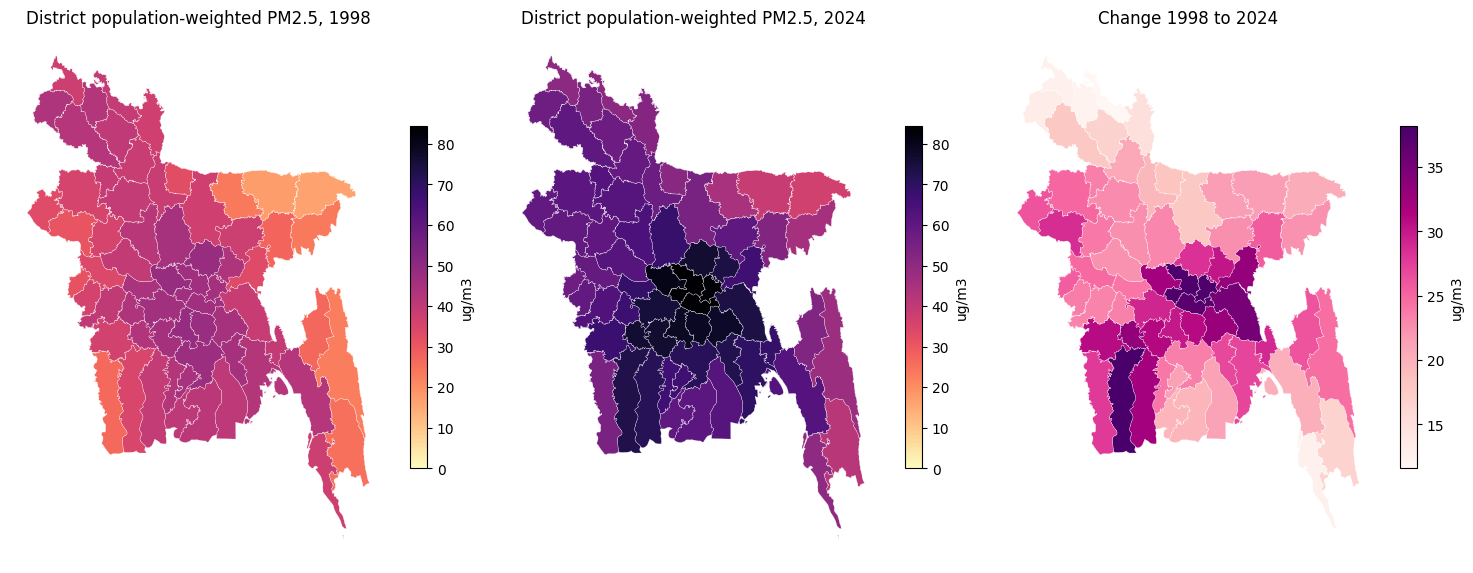

In [9]:
dmap = district.merge(unit_year.query("level == 'district' and year in [@YEARS[0], @YEARS[-1]]").pivot(index="pcode", columns="year", values="pm25_popw").reset_index())
fig, ax = plt.subplots(1, 3, figsize=(15, 6))
for a, y in zip(ax[:2], (YEARS[0], YEARS[-1])):
    dmap.plot(column=y, ax=a, cmap="magma_r", vmin=0, vmax=dmap[[YEARS[0], YEARS[-1]]].max().max(), legend=True, legend_kwds={"label": "ug/m3", "shrink": 0.6}, edgecolor="white", linewidth=0.2)
    a.set_title(f"District population-weighted PM2.5, {y}"); a.set_axis_off()
dmap.assign(change=dmap[YEARS[-1]] - dmap[YEARS[0]]).plot(column="change", ax=ax[2], cmap="RdPu", legend=True, legend_kwds={"label": "ug/m3", "shrink": 0.6}, edgecolor="white", linewidth=0.2)
ax[2].set_title(f"Change {YEARS[0]} to {YEARS[-1]}"); ax[2].set_axis_off()
plt.tight_layout(); plt.savefig(FIG / "02_district_maps.png", dpi=150)

## 5. Monthly means

The same population-weighted sums for every month on the 0.1° grid. These feed the seasonality analysis in R (STL decomposition, month-by-district heatmap). The 0.1° grid is coarser, so monthly values can differ slightly from the annual 0.01° values; section 6 compares them.

In [10]:
mrows = []
for k, t in enumerate(tqdm(mon["time"].values, desc="Months")):
    pxp, p = sums(mon.values[k].ravel(), fm)
    mrows.append(pd.DataFrame({"upazila_pcode": upazila["pcode"], "date": pd.Timestamp(t), "pm_x_pop": pxp, "pop": p}))
unit_month = roll(pd.concat(mrows, ignore_index=True), ["pm_x_pop", "pop"]).assign(pm25_popw=lambda d: d["pm_x_pop"] / d["pop"])[["level", "pcode", "name", "date", "pm25_popw"]].sort_values(["level", "pcode", "date"])
unit_month.to_parquet(PROC / "pm25_unit_month.parquet", index=False)
natm = unit_month.query("level == 'national'").set_index("date")["pm25_popw"]
print(f"Monthly rows: {len(unit_month):,} | national months: {len(natm)}, missing: {natm.isna().sum()}")

Months:   0%|          | 0/324 [00:00<?, ?it/s]

Monthly rows: 187,920 | national months: 324, missing: 0


## 6. Checking the 2018 jump (fix 2)

In notebook 01, 2018 stood out at about 77 µg/m³ (area mean) against 55 to 64 in the years around it. Three checks decide whether it is a processing error or part of the data:

1. **Annual vs monthly:** if the yearly mean of the 12 monthly 0.1° files also jumps in 2018, the jump is not a problem with one annual file.
2. **Which months:** if the jump comes from a few months, it points to a seasonal episode; if every month is higher, it points to a shift in the whole year's estimate.
3. **Previous release:** the earlier ACAG release V6.GL.02.04 is built with older inputs and a different model version. If it shows the same jump, the jump comes from the satellite data both releases share, not from one release.

ACAG's own country-level summary file sits on Box only, so the previous release is used as the independent comparison instead.

In [11]:
j = YEARS.index(2018) if 2018 in YEARS else None
assert j is not None and 0 < j < len(YEARS) - 1, "2018 is not inside the year range"
annual_vs_monthly = pd.DataFrame({"annual_0p01": nat["pm25_popw"], "monthly_0p1_mean": natm.groupby(natm.index.year).mean()}).round(1)
jump = lambda s: (s.loc[2018] / s.loc[[2017, 2019]].mean() - 1) * 100

clim = natm.groupby(natm.index.month).mean()
month_2018 = pd.DataFrame({"2018": natm[natm.index.year == 2018].values, "all_years_mean": clim.values, "2017": natm[natm.index.year == 2017].values, "2019": natm[natm.index.year == 2019].values}, index=pd.Index(range(1, 13), name="month")).round(1)
month_2018["2018_vs_mean_%"] = ((month_2018["2018"] / month_2018["all_years_mean"] - 1) * 100).round(0)
print(f"2018 vs average of 2017 and 2019: annual 0.01 deg {jump(annual_vs_monthly['annual_0p01']):+.0f}%, monthly 0.1 deg {jump(annual_vs_monthly['monthly_0p1_mean']):+.0f}%")
month_2018

2018 vs average of 2017 and 2019: annual 0.01 deg +28%, monthly 0.1 deg +28%


,2018,all_years_mean,2017,2019,2018_vs_mean_%
month,,,,,
1,161.6,121.2,114.6,131.2,33.0
2,133.2,101.8,116.5,109.1,31.0
3,96.7,73.4,54.9,88.7,32.0
4,63.1,43.9,39.6,55.1,44.0
5,39.3,35.3,41.3,41.5,11.0
6,43.5,30.7,34.7,38.6,42.0
7,35.8,26.3,30.7,31.3,36.0
8,35.0,28.4,30.6,33.8,23.0
9,46.1,28.1,39.2,26.9,64.0


In [12]:
listing = pd.read_parquet(ROOT / "data" / "parquet" / "pm25_s3_listing.parquet")
prev = {y: listing.loc[listing["key"].str.contains(rf"V6GL0204/CNNPM25/Annual/AS/.*\.{y}01-{y}12\.nc$"), "key"] for y in range(2016, 2021)}
S3, W, E, S, N = "https://satpmdata.s3.amazonaws.com", 87.9, 92.8, 20.5, 26.7
prev_mean = {}
for y, keys in tqdm(prev.items(), desc="V6.GL.02.04"):
    assert len(keys) == 1, f"No V6.GL.02.04 Asia file found for {y}"
    tmp = TMP / f"prev_{y}.nc"
    with requests.get(f"{S3}/{quote(keys.iloc[0])}", stream=True, timeout=300) as r, open(tmp, "wb") as f:
        r.raise_for_status(); [f.write(ch) for ch in r.iter_content(1 << 22)]
    with xr.open_dataset(tmp) as ds:
        ds = ds.rename({k: v for k, v in {"latitude": "lat", "longitude": "lon"}.items() if k in ds.variables})
        da = ds[next(v for v in ds.data_vars if "pm" in v.lower())]
        da = da.sel(lat=slice(S, N) if da["lat"][0] < da["lat"][-1] else slice(N, S), lon=slice(W, E)).squeeze(drop=True).sortby("lat").load()
    tmp.unlink()
    v = da.interp(lat=ann["lat"], lon=ann["lon"], method="nearest").values.ravel()[fa]
    prev_mean[y] = np.nansum(w * v) / w[~np.isnan(v)].sum()
releases = pd.DataFrame({"V6.GL.03 (used)": nat.loc[list(prev), "pm25_popw"], "V6.GL.02.04 (previous)": pd.Series(prev_mean)}).round(1)
print(f"2018 vs average of 2017 and 2019: V6.GL.03 {jump(releases.iloc[:, 0]):+.0f}%, V6.GL.02.04 {jump(releases.iloc[:, 1]):+.0f}%")
qa += [{"check": "2018 jump, annual 0.01 deg", "value": f"{jump(annual_vs_monthly['annual_0p01']):+.0f}%"},
       {"check": "2018 jump, monthly 0.1 deg", "value": f"{jump(annual_vs_monthly['monthly_0p1_mean']):+.0f}%"},
       {"check": "2018 jump, previous release V6.GL.02.04", "value": f"{jump(releases.iloc[:, 1]):+.0f}%"}]
releases

V6.GL.02.04:   0%|          | 0/5 [00:00<?, ?it/s]

2018 vs average of 2017 and 2019: V6.GL.03 +28%, V6.GL.02.04 +3%


,V6.GL.03 (used),V6.GL.02.04 (previous)
2016,65.2,56.8
2017,60.5,57.4
2018,83.3,63.9
2019,69.5,66.9
2020,70.3,62.6


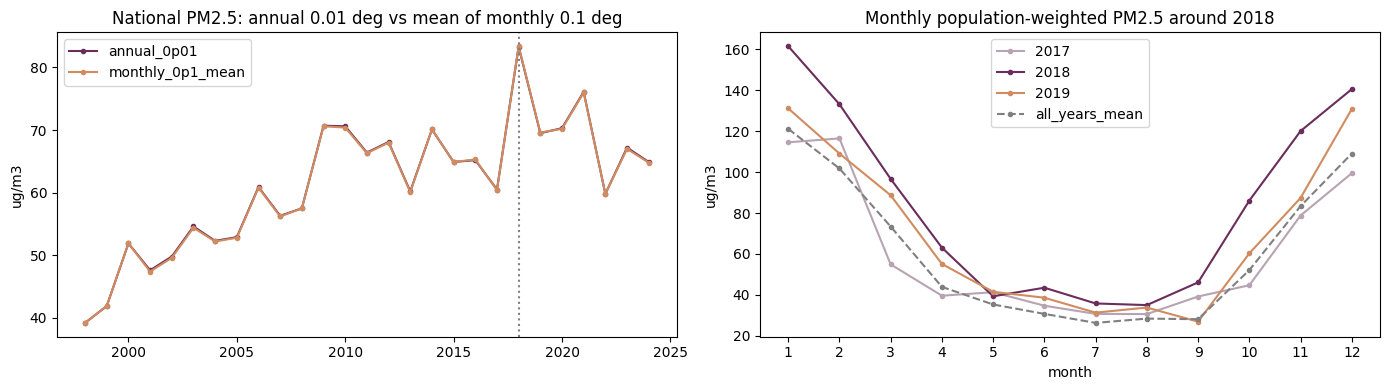

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
annual_vs_monthly.plot(ax=ax[0], marker="o", ms=3, color=["#6b2d5c", "#d08c60"])
ax[0].axvline(2018, ls=":", color="grey"); ax[0].set(title="National PM2.5: annual 0.01 deg vs mean of monthly 0.1 deg", ylabel="ug/m3", xlabel="")
month_2018[["2017", "2018", "2019", "all_years_mean"]].plot(ax=ax[1], marker="o", ms=3, color=["#b8a3b3", "#6b2d5c", "#d08c60", "grey"], style=["-", "-", "-", "--"])
ax[1].set(title="Monthly population-weighted PM2.5 around 2018", ylabel="ug/m3", xticks=range(1, 13))
plt.tight_layout(); plt.savefig(FIG / "02_check_2018.png", dpi=150)

**How to read the 2018 checks**
- If the jump appears in the annual and the monthly files and in both releases, it is part of the satellite estimate, not a download or processing error. The year is kept, and the report says that 2018 is unusually high in the satellite record and that the trend tests in R are robust to single years (Sen's slope uses medians).
- If the jump appears only in V6.GL.03, it is specific to the newest release; it is still kept for consistency, and the report flags it.
- If the annual and monthly files disagree strongly for 2018 only, that one annual file is suspect and should be re-downloaded.

## 7. Quality checks

In [14]:
qa = pd.DataFrame(qa)
qa.to_csv(PROC / "qa_checks.csv", index=False)
assert float(gaps["missing_people_%"].max()) < 1, "More than 1% of people live in cells with no PM2.5 value"
assert abs(float(pop_grid.sum()) - w.sum()) < 1, "Population changed when moved to the PM2.5 grid"
shutil.rmtree(TMP, ignore_errors=True)
qa

,check,value
0,people snapped to nearest upazila,"21,135 (0.013%), max 3.2 km"
1,population total,"168,343,283"
2,cells inside Bangladesh (0.01 deg),"129,302"
3,"max missing cells inside border, any year",0.0%
4,"max missing people, any year",0.0%
5,upazilas with no 0.01 deg cell centre,0
6,"population in weighted means (national, any year)","168,343,283 to 168,343,283"
7,"2018 jump, annual 0.01 deg",+28%
8,"2018 jump, monthly 0.1 deg",+28%
9,"2018 jump, previous release V6.GL.02.04",+3%


## Next: notebook 03, DuckDB SQL

About ten queries on `pm25_unit_year`, `pm25_unit_month` and `pm25_who_bands`: national and division summaries, district and upazila rankings, the 1998 vs 2024 change, people above each WHO band, the worst upazilas, and the seasonal peak month by division.